# 05 — Inventory Optimization: from forecasts to money

A forecast is only useful if it improves a **decision**. This notebook converts the demand forecasts into daily ordering decisions for Q4 2017 and measures the result in cost, not SMAPE.

**Scenario.** Stock for each (store, item, day) must be committed **91 days in advance** (the lead time matching the backtest horizon of [`04_evaluation.ipynb`](04_evaluation.ipynb)). Each day is a newsvendor problem:

- order too little → lost sales at **$2.00** margin per unit (underage cost)
- order too much → **$0.20** per unit of leftover (holding/spoilage, overage cost)

Newsvendor theory gives the optimal service level as the critical ratio *Cu / (Cu + Co)* = 2.0 / 2.2 ≈ **91%** — so the cost-optimal order is not the median forecast but the **91st percentile** of demand. Point forecasts, however accurate, cannot express that. We need **quantile forecasts**.

**Policies compared** (stock level for each series-day):

1. **Naive** — last year's same-weekday sales (`lag_364`), no model
2. **LightGBM P50** — an accurate *point* forecast (median)
3. **LightGBM P90 / P95** — quantile forecasts bracketing the critical ratio

> Simplification: no inventory carryover between days (perishable-style). This isolates the forecasting contribution to the ordering decision; a full simulation would add carryover, order batching and lead-time pooling.

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path

from src.data.load import load_raw
from src.features.build_features import build_features
from src.models.train import train_lgbm

PALETTE = ["#2a78d6", "#008300", "#e87ba4", "#eda100", "#1baf7a", "#eb6834", "#4a3aa7", "#e34948"]
BLUE, GREEN = PALETTE[0], PALETTE[1]
BAND = "#cde2fb"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "figure.dpi": 110, "font.size": 11,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

FIG_DIR = Path("../outputs/figures")
METRICS_DIR = Path("../outputs/metrics")

STOCKOUT_COST = 2.00   # lost margin per unit short (Cu)
HOLDING_COST = 0.20    # per unit left over (Co)
CRITICAL_RATIO = STOCKOUT_COST / (STOCKOUT_COST + HOLDING_COST)
print(f"Critical ratio (optimal service level): {CRITICAL_RATIO:.1%}")

Critical ratio (optimal service level): 90.9%


## 1. Data — same horizon-safe setup as the backtest

Features from [`src/features/build_features.py`](../src/features/build_features.py) with `horizon=91`. Train on everything before Q4 2017 (last 91 days held out for early stopping), decide stock for every day of Q4.

In [2]:
HORIZON = 91
Q4_START, Q4_END = "2017-10-01", "2018-01-01"

df = load_raw("../data/raw/train.csv")
df = build_features(df, lags=(91, 98, 182, 364, 365), windows=(28, 91), horizon=HORIZON)
df["store"] = df["store"].astype("category")
df["item"] = df["item"].astype("category")

FEATURES = [c for c in df.columns if c not in ("date", "sales")]

test = df[(df["date"] >= Q4_START) & (df["date"] < Q4_END)]
known = df[df["date"] < Q4_START]
es_cut = pd.Timestamp(Q4_START) - pd.Timedelta(days=HORIZON)
fit = known[known["date"] < es_cut]
es = known[known["date"] >= es_cut]

print(f"Fit: {len(fit):,} rows | early-stop holdout: {len(es):,} | Q4 decisions: {len(test):,}")

Fit: 639,000 rows | early-stop holdout: 45,500 | Q4 decisions: 46,000


## 2. Quantile LightGBM models

Same features and hyperparameters as the backtest, but with LightGBM's `quantile` objective (pinball loss) at α = 0.50, 0.90, 0.95. Each model learns a different point of the demand distribution — P90 sits above P50 exactly enough to cover the series' own volatility.

In [3]:
quantile_preds = {}
for alpha in (0.50, 0.90, 0.95):
    model = train_lgbm(
        fit[FEATURES], fit["sales"], es[FEATURES], es["sales"],
        params={"objective": "quantile", "alpha": alpha},
        eval_metric="quantile",
    )
    quantile_preds[alpha] = model.predict(test[FEATURES], num_iteration=model.best_iteration_)
    coverage = (test["sales"].to_numpy() <= quantile_preds[alpha]).mean()
    print(f"P{int(alpha * 100)}: trained ({model.best_iteration_} trees) | "
          f"empirical coverage on Q4: {coverage:.1%} (target {alpha:.0%})")

P50: trained (1393 trees) | empirical coverage on Q4: 52.0% (target 50%)


P90: trained (1498 trees) | empirical coverage on Q4: 89.3% (target 90%)


P95: trained (1075 trees) | empirical coverage on Q4: 94.2% (target 95%)


## 3. Simulating the ordering policies

For each policy, stock is rounded to whole units. Selling `min(stock, demand)` each day, we accumulate holding cost on leftovers and lost margin on shortfalls.

In [4]:
def simulate(name, stock, demand):
    stock = np.maximum(np.round(stock), 0)
    sold = np.minimum(stock, demand)
    leftover = stock - sold
    short = demand - sold
    holding = leftover.sum() * HOLDING_COST
    stockout = short.sum() * STOCKOUT_COST
    return {"policy": name,
            "fill rate %": sold.sum() / demand.sum() * 100,
            "days with stockout %": (short > 0).mean() * 100,
            "holding cost $": holding,
            "lost margin $": stockout,
            "total cost $": holding + stockout}

demand = test["sales"].to_numpy().astype(float)

policies = [
    simulate("Naive (lag-364)", test["sales_lag_364"].to_numpy(), demand),
    simulate("LightGBM P50", quantile_preds[0.50], demand),
    simulate("LightGBM P90", quantile_preds[0.90], demand),
    simulate("LightGBM P95", quantile_preds[0.95], demand),
]
sim = pd.DataFrame(policies).set_index("policy")
sim.round(1)

,fill rate %,days with stockout %,holding cost $,lost margin $,total cost $
policy,,,,,
Naive (lag-364),90.3,56.0,28049.2,488048.0,516097.2
LightGBM P50,94.7,45.2,27985.0,264164.0,292149.0
LightGBM P90,99.2,9.5,90377.6,38492.0,128869.6
LightGBM P95,99.6,5.1,114399.4,19230.0,133629.4


## 4. Cost and service level

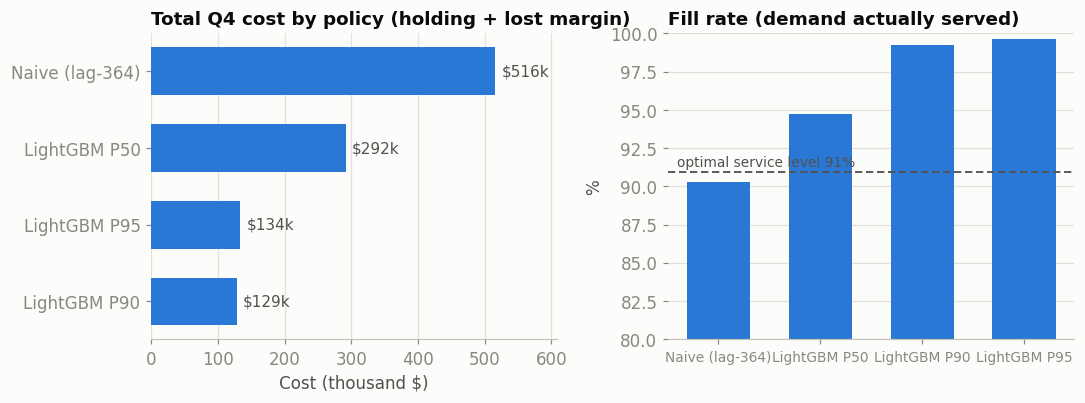

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))

order = sim.sort_values("total cost $", ascending=True)
bars = ax1.barh(order.index, order["total cost $"] / 1000, color=BLUE, height=0.62)
ax1.bar_label(bars, fmt="$%.0fk", padding=4, color=INK2, fontsize=10)
ax1.set_title("Total Q4 cost by policy (holding + lost margin)")
ax1.set_xlabel("Cost (thousand $)")
ax1.set_xlim(0, order["total cost $"].max() / 1000 * 1.18)
ax1.grid(axis="x")
ax1.grid(axis="y", visible=False)

bars2 = ax2.bar(sim.index, sim["fill rate %"], color=BLUE, width=0.62)
ax2.axhline(CRITICAL_RATIO * 100, color=INK2, linewidth=1.2, linestyle=(0, (4, 2)))
ax2.text(-0.4, CRITICAL_RATIO * 100 + 0.4, f"optimal service level {CRITICAL_RATIO:.0%}",
         color=INK2, fontsize=9)
ax2.set_title("Fill rate (demand actually served)")
ax2.set_ylabel("%")
ax2.set_ylim(80, 100)
ax2.tick_params(axis="x", labelsize=9)
ax2.grid(axis="y")
ax2.grid(axis="x", visible=False)

fig.tight_layout()
fig.savefig(FIG_DIR / "inv_01_cost_service.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. What safety stock looks like

For one series: the P90 order level rides above the median forecast by a margin that widens exactly when the series is more volatile — that gap **is** the safety stock, learned from data instead of a fixed rule of thumb.

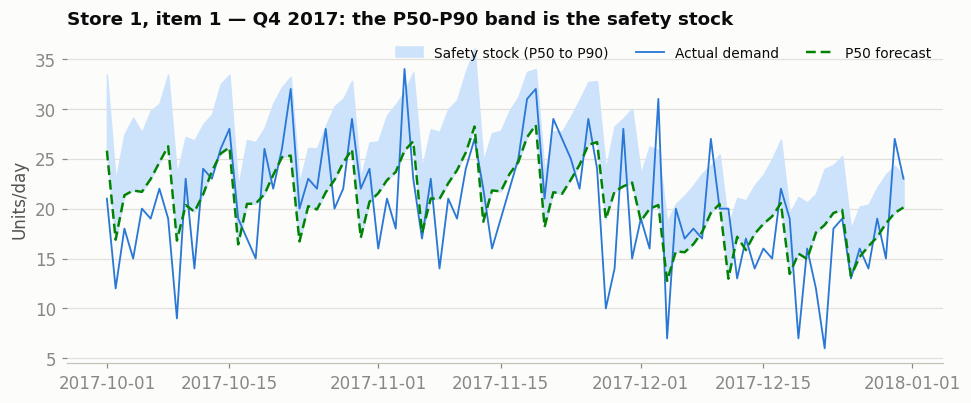

In [6]:
mask = (test["store"] == 1) & (test["item"] == 1)
one = test[mask].set_index("date")
p50_one = quantile_preds[0.50][mask.to_numpy()]
p90_one = quantile_preds[0.90][mask.to_numpy()]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.fill_between(one.index, p50_one, p90_one, color=BAND, label="Safety stock (P50 to P90)")
ax.plot(one.index, one["sales"], color=BLUE, linewidth=1.2, label="Actual demand")
ax.plot(one.index, p50_one, color=GREEN, linewidth=1.6, linestyle=(0, (4, 2)), label="P50 forecast")
ax.set_title("Store 1, item 1 — Q4 2017: the P50-P90 band is the safety stock")
ax.set_ylabel("Units/day")
ax.legend(frameon=False, loc="upper right", ncols=3, fontsize=9)
ax.grid(axis="y")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "inv_02_safety_stock.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Persist results

In [7]:
sim.round(2).to_csv(METRICS_DIR / "inventory_simulation.csv")
best = sim["total cost $"].idxmin()
naive_cost = sim.loc["Naive (lag-364)", "total cost $"]
best_cost = sim.loc[best, "total cost $"]
print(f"Best policy: {best}")
print(f"Cost vs naive policy: ${naive_cost - best_cost:,.0f} saved in one quarter "
      f"({(1 - best_cost / naive_cost) * 100:.0f}% lower)")

Best policy: LightGBM P90
Cost vs naive policy: $387,228 saved in one quarter (75% lower)


## Summary

| Policy | Fill rate | Days with stockout | Total Q4 cost |
|---|---|---|---|
| Naive (lag-364) | 90.3% | 56.0% | $516k |
| LightGBM P50 (point forecast) | 94.7% | 45.2% | $292k |
| **LightGBM P90** | **99.2%** | **9.5%** | **$129k — best** |
| LightGBM P95 | 99.6% | 5.1% | $134k |

- **The quantile models are well calibrated**: empirical Q4 coverage of 52% / 89% / 94% against targets of 50% / 90% / 95% — the uncertainty estimates can be trusted enough to order against.
- **Accuracy alone cut costs by 43%** (naive → P50), but **ordering at the quantile matching the critical ratio cut them by 75%**. The gap between those two numbers is the value of forecasting the *distribution* instead of a point.
- **P95 loses to P90**, exactly as newsvendor theory predicts (optimum ≈ P91): pushing service past the critical ratio buys holding cost faster than it saves margin.

**Caveats:** cost parameters are illustrative and the simulation has no inventory carryover; the *direction* of the conclusion — distribution-aware ordering dominates point-forecast ordering — is robust to both.